# 08. Terceira base intocada: SpamAssassin (decisão D10, pré-registrada)

**Pergunta:** o Stacking 8 (o Stacking 7 + o TabPFN, modelo de fundação para tabelas) deve substituir o
Stacking 7 padrão como o stacking para caixas de e-mail novas?

Na base externa (Enron2-6), o Stacking 8 custou menos. Mas esse achado veio de *olhar* a base externa; usá-lo
para escolher faria dela uma base de seleção. Por isso a regra foi **escrita antes** (D10 no registro de
decisões) e é aplicada aqui numa base que nenhuma escolha anterior tinha usado:

> O Stacking 8 padrão substitui o Stacking 7 padrão se reduzir o custo por mil e-mails (limiar de custo, λ = 9)
> com P(redução) ≥ 0,90 no bootstrap por grupo, sem piorar o MCC no limiar de custo em mais de 0,01.

(No texto original da regra, o vencedor "vira o Generalista". Depois da revisão crítica, o rótulo foi trocado
pelo nome do método, Stacking 8: ver D11 no registro.) Depois desta decisão, o SpamAssassin também é uma base
usada para escolher; não sobra base externa intocada.

**A base.** SpamAssassin public corpus (2002-2003): 6047 mensagens brutas, de outras pessoas e outra época,
convertidas para o formato da AUEB por `spamfilter.conversao` e contadas com o vocabulário do CSV. O conversor
reproduz exatamente 90,5% dos e-mails reais brutos da caixa farmer-d; no spam, a validação está na seção 6.
Treino: os 5172 e-mails do CSV, sem ajuste.

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/notebooks/08_terceira_base.ipynb)

**No Google Colab:** rode tudo (*Ambiente de execução → Executar tudo*). Na primeira vez, a célula abaixo baixa o
projeto, instala os pacotes e **reinicia o ambiente**; quando o Colab reconectar, use *Executar tudo* de novo.
No computador, ela não faz nada (siga o [INSTALACAO.md](https://github.com/felipe44776-eseg/filtro-spam-stacking-enron/blob/main/INSTALACAO.md)).

In [1]:
# Google Colab: prepara o ambiente na primeira execução. No computador, esta célula não faz nada.
import os, subprocess, sys
if "google.colab" in sys.modules:
    PROJETO = "/content/filtro-spam-stacking-enron"
    if not os.path.isdir(PROJETO):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/felipe44776-eseg/filtro-spam-stacking-enron.git", PROJETO], check=True)
    os.chdir(PROJETO)
    sys.path.insert(0, PROJETO)
    MARCA = "/content/.spamfilter_instalado"
    if not os.path.exists(MARCA):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
        open(MARCA, "w").close()
        print("Pacotes instalados. O Colab vai reiniciar o ambiente: quando reconectar, use Executar tudo de novo.")
        os.kill(os.getpid(), 9)

In [2]:
import json
import re
import tarfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spamfilter import caminhos, estatistica, externo, graficos, metricas, modelos, saidas
from spamfilter.dados import carregar
from spamfilter.motor import Motor

base = carregar()
Xsa, ysa, gsa, mantidas = externo.carregar_spamassassin(base)
print(f"SpamAssassin: {len(ysa)} mensagens ({(ysa == 0).sum()} e-mails reais, {(ysa == 1).sum()} spams; "
      f"{(~mantidas).sum()} cópia(s) do CSV removida(s))")

SpamAssassin: 6046 mensagens (4150 e-mails reais, 1896 spams; 1 cópia(s) do CSV removida(s))


## 1. Os 7 membros: reaproveita as notas out-of-fold da base externa e treina só o modelo final

In [3]:
m = Motor(base, cache=caminhos.RESULTADOS / "cache_motor", leitura_extra=[caminhos.CACHE_MOTOR], log=print)
m.adicionar_externo({})
P, E = modelos.STACKING7_PADRAO, modelos.STACKING7_ESPECIALISTA
pares = sorted({(f, cfg[i]) for cfg in (P, E) for i, f in enumerate(modelos.FAMILIAS)} | {("LinearSVC", modelos.LINEARSVC_PADRAO)}, key=str)
m.estender("externo", "spamassassin", {"SpamAssassin": Xsa}, pares)

estender externo -> spamassassin: 15 configurações, 0 pendentes
estender spamassassin: 0s


'spamassassin'

## 2. O TabPFN (nuvem, TabPFN-3.5-Plus)
Nota out-of-fold no treino: a mesma da base externa (experimento 05). Nota na base nova: `scripts/tabpfn_nuvem_prever.py`.

In [4]:
arq_tab = caminhos.RESULTADOS / "cache_tabpfn" / "spamassassin.npz"
tem_tabpfn = arq_tab.exists()
if tem_tabpfn:
    ztr_tab = np.load(caminhos.EXPERIMENTOS / "05_tabpfn" / "cache_tabpfn" / "nuvem" / "externo.npz")["ztr"]
    zte_tab = np.load(arq_tab)["zte"][mantidas]
    print(f"TabPFN: {len(zte_tab)} notas")
else:
    print("notas do TabPFN ausentes (rode scripts/tabpfn_nuvem_prever.py com a chave): só os métodos sem TabPFN")

TabPFN: 6046 notas


## 3. Resultado

In [5]:
from spamfilter.metricas import limiar_custo
te = "SpamAssassin"
PREV = {"Stacking 7 padrão": m.prever_stacking(P, "spamassassin", te),
        "Stacking 7 especialista": m.prever_stacking(E, "spamassassin", te),
        "LinearSVC padrão": m.prever_linearsvc(modelos.LINEARSVC_PADRAO, "spamassassin", te),
        "Não filtrar (referência)": (np.zeros(len(ysa)), np.zeros(len(ysa), int), np.zeros(len(ysa), int))}
ytr = m.y_treino("spamassassin")
if tem_tabpfn:
    PREV["Stacking 8 padrão (+TabPFN)"] = m.prever_stacking(P, "spamassassin", te, extra=(ztr_tab, zte_tab))
    PREV["Stacking 8 especialista (+TabPFN)"] = m.prever_stacking(E, "spamassassin", te, extra=(ztr_tab, zte_tab))
    PREV["TabPFN-3.5-Plus sozinho"] = (zte_tab, (zte_tab > 0.5).astype(int), (zte_tab > limiar_custo(ztr_tab, ytr)).astype(int))

R = pd.DataFrame([dict(metodo=k, **metricas.metricas(ysa, *v)) for k, v in PREV.items()]).sort_values("custo_por_mil")
mostra = R[["metodo", "mcc_custo", "pr_auc", "real_lixeira_custo", "spam_passou_custo", "custo_por_mil", "mcc"]].copy()
mostra[["real_lixeira_custo", "spam_passou_custo"]] *= 100
print(mostra.round(3).to_string(index=False))

                           metodo  mcc_custo  pr_auc  real_lixeira_custo  spam_passou_custo  custo_por_mil   mcc
         Não filtrar (referência)      0.000   0.314               0.000            100.000        313.596 0.000
          TabPFN-3.5-Plus sozinho      0.357   0.635               4.602             69.884        503.473 0.337
                 LinearSVC padrão      0.553   0.770               6.289             44.620        528.449 0.490
Stacking 8 especialista (+TabPFN)      0.387   0.639              13.590             50.316        997.354 0.300
      Stacking 8 padrão (+TabPFN)      0.437   0.668              16.048             40.981       1119.914 0.314
                Stacking 7 padrão      0.415   0.684              30.747             24.789       1977.175 0.276
          Stacking 7 especialista      0.350   0.652              37.880             24.367       2416.474 0.269


## 4. Aplicando a regra pré-registrada

In [6]:
A_, B_ = "Stacking 8 padrão (+TabPFN)", "Stacking 7 padrão"
decisao = None
if tem_tabpfn:
    _, inv = np.unique(gsa, return_inverse=True)
    membros = [np.flatnonzero(inv == k) for k in range(inv.max() + 1)]
    rng = np.random.default_rng(42); dif = []
    for _ in range(2000):
        sel = np.concatenate([membros[k] for k in rng.integers(0, len(membros), len(membros))])
        dif.append(metricas.custo_por_mil(ysa[sel], PREV[A_][2][sel]) - metricas.custo_por_mil(ysa[sel], PREV[B_][2][sel]))
    dif = np.array(dif)
    p_reduz = float((dif < 0).mean())
    d_custo = float(R.set_index("metodo").loc[A_, "custo_por_mil"] - R.set_index("metodo").loc[B_, "custo_por_mil"])
    d_mcc = float(R.set_index("metodo").loc[A_, "mcc_custo"] - R.set_index("metodo").loc[B_, "mcc_custo"])
    na, nb, p_mc = estatistica.mcnemar(PREV[A_][2] == ysa, PREV[B_][2] == ysa)
    troca = (p_reduz >= 0.90) and (d_mcc >= -0.01)
    decisao = dict(diferenca_custo=d_custo, ic95_custo=[float(np.quantile(dif, 0.025)), float(np.quantile(dif, 0.975))],
                   p_reducao=p_reduz, diferenca_mcc_custo=d_mcc, mcnemar=dict(so_stacking8_acerta=na, so_stacking7_acerta=nb, p=p_mc),
                   stacking8_vira_generalista=bool(troca))
    print(f"custo: Stacking 8 − Stacking 7 = {d_custo:+.1f} por mil (IC95 {np.quantile(dif, 0.025):+.1f} a {np.quantile(dif, 0.975):+.1f}); "
          f"P(redução) = {p_reduz:.3f}")
    print(f"MCC no limiar de custo: {d_mcc:+.4f} | McNemar: só o S8 acerta {na}, só o S7 acerta {nb}, p = {p_mc:.3g}")
    print("DECISÃO (regra D10):", "o Stacking 8 padrão substitui o Stacking 7 padrão" if troca else "o Stacking 7 padrão continua")
nao_filtrar = 1000 * float(ysa.mean())
print(f"\nreferência: não filtrar nada custa {nao_filtrar:.1f} por mil (todo spam passa, nenhum e-mail real se perde). "
      f"Mais barato que isso: {', '.join(R[R.custo_por_mil < nao_filtrar].metodo) or 'nenhum filtro'}")

custo: Stacking 8 − Stacking 7 = -857.3 por mil (IC95 -929.2 a -789.3); P(redução) = 1.000
MCC no limiar de custo: +0.0221 | McNemar: só o S8 acerta 611, só o S7 acerta 308, p = 8.78e-24
DECISÃO (regra D10): o Stacking 8 padrão substitui o Stacking 7 padrão

referência: não filtrar nada custa 313.6 por mil (todo spam passa, nenhum e-mail real se perde). Mais barato que isso: nenhum filtro


### O resultado depende de λ?
A regra D10 foi escrita com λ = 9. Para ver se a conclusão muda com o peso do erro, o limiar é re-escolhido no
treino para cada λ (isto não muda a decisão: é só leitura).

In [7]:
lam_lin = []
for lam in [1, 3, 9, 20]:
    cand = {"Stacking 7 padrão": m.prever_stacking(P, "spamassassin", te, custo_fp=lam)[2],
            "LinearSVC padrão": m.prever_linearsvc(modelos.LINEARSVC_PADRAO, "spamassassin", te, custo_fp=lam)[2],
            "Não filtrar (referência)": np.zeros(len(ysa), int)}
    if tem_tabpfn:
        cand["Stacking 8 padrão (+TabPFN)"] = m.prever_stacking(P, "spamassassin", te, extra=(ztr_tab, zte_tab), custo_fp=lam)[2]
        cand["TabPFN-3.5-Plus sozinho"] = (zte_tab > limiar_custo(ztr_tab, ytr, lam, 1)).astype(int)
    for nome, yc in cand.items():
        lam_lin.append(dict(custo_fp=lam, metodo=nome, custo_por_mil=metricas.custo_por_mil(ysa, yc, lam, 1)))
LAM = pd.DataFrame(lam_lin)
print(LAM.pivot(index="metodo", columns="custo_fp", values="custo_por_mil").round(1).to_string())

custo_fp                        1      3       9      20
metodo                                                  
LinearSVC padrão             247.8  321.2   528.4  762.7
Não filtrar (referência)     313.6  313.6   313.6  313.6
Stacking 7 padrão            395.1  888.0  1977.2  696.3
Stacking 8 padrão (+TabPFN)  352.5  846.5  1119.9  599.4
TabPFN-3.5-Plus sozinho      289.3  570.6   503.5  420.8


## 5. Todos vão mal. A culpa é da representação ou da caixa?
Teste de controle: treinar e testar **dentro** do SpamAssassin, com a mesma conversão e o mesmo vocabulário
(uma Reg. Logística, limiar 0,5). Se der alto, a representação tem sinal lá e a queda vem da mudança de caixa.
O controle **não** prova que a conversão reproduz a da AUEB: isso é a seção 6.

In [8]:
import random
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, matthews_corrcoef
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from spamfilter import conversao, representacao

lr_sa = make_pipeline(representacao.tfidf(), LogisticRegression(C=10, max_iter=3000, class_weight="balanced"))
p_in = cross_val_predict(lr_sa, Xsa, ysa, cv=StratifiedGroupKFold(5, shuffle=True, random_state=42), groups=gsa, method="predict_proba")[:, 1]
dentro = dict(mcc=float(matthews_corrcoef(ysa, p_in > 0.5)), pr_auc=float(average_precision_score(ysa, p_in)))
random.seed(1)
brutos_sa, _, _ = externo.ler_spamassassin()
cob = {"Enron1 (treino)": externo.ler_tar(1)[0], "Enron3": externo.ler_tar(3)[0]}
cob = {k: float(np.mean([conversao.cobertura(t, base.vocab) for t in random.sample(v, 300)])) for k, v in cob.items()}
cob["SpamAssassin"] = float(np.mean([conversao.cobertura(conversao.para_aueb(b), base.vocab) for b in random.sample(brutos_sa, 300)]))
print(f"Reg. Logística treinada e testada dentro do SpamAssassin: MCC {dentro['mcc']:.3f} | PR-AUC {dentro['pr_auc']:.3f}")
print("cobertura do vocabulário (fração das palavras do texto que o vocabulário conhece):",
      {k: f"{v:.1%}" for k, v in cob.items()})

Reg. Logística treinada e testada dentro do SpamAssassin: MCC 0.968 | PR-AUC 0.998
cobertura do vocabulário (fração das palavras do texto que o vocabulário conhece): {'Enron1 (treino)': '81.6%', 'Enron3': '77.2%', 'SpamAssassin': '65.4%'}


### Quem erra o quê: por pasta do SpamAssassin e por membro do stacking
As pastas `easy_ham`, `easy_ham_2` e `hard_ham` são e-mails reais; `spam` e `spam_2`, spam. Para cada membro do
Stacking 7 padrão: a fração de e-mails reais com nota acima de 0,5, o PR-AUC no SpamAssassin e o peso que o
meta-modelo, treinado na caixa farmer-d, dá a ele.

In [9]:
nomes_sa = np.load(externo.VETORES_SPAMASSASSIN)["nomes"][mantidas]
pasta_sa = np.array([str(nm).split("/")[-2] for nm in nomes_sa])
dec_pasta = {k: PREV[k][2] for k in ["Stacking 7 padrão", "Stacking 8 padrão (+TabPFN)", "TabPFN-3.5-Plus sozinho", "LinearSVC padrão"] if k in PREV}
PASTAS = pd.DataFrame([dict(pasta=p, n=int((pasta_sa == p).sum()), **{k: float(v[pasta_sa == p].mean()) for k, v in dec_pasta.items()})
                       for p in sorted(set(pasta_sa))])
print("fração marcada como spam (limiar de custo), por pasta:\n" + PASTAS.round(3).to_string(index=False))
Ztr_m = np.column_stack([m.carregar("spamassassin", f, P[i], te)[0] for i, f in enumerate(modelos.FAMILIAS)])
peso = modelos.meta(modelos.META_C[P[-1]]).fit(Ztr_m, base.y)[-1].coef_.ravel()
memb = []
for i, f in enumerate(modelos.FAMILIAS):
    _, z = m.carregar("spamassassin", f, P[i], te)
    memb.append(dict(membro=f, reais_acima_de_05=float(np.mean(z[ysa == 0] > 0.5)), spam_abaixo_de_05=float(np.mean(z[ysa == 1] <= 0.5)),
                     pr_auc=float(average_precision_score(ysa, z)), peso_meta=float(peso[i])))
MEMB = pd.DataFrame(memb)
print("\nmembros do Stacking 7 padrão no SpamAssassin:\n" + MEMB.round(3).to_string(index=False))

fração marcada como spam (limiar de custo), por pasta:
     pasta    n  Stacking 7 padrão  Stacking 8 padrão (+TabPFN)  TabPFN-3.5-Plus sozinho  LinearSVC padrão
  easy_ham 2500              0.326                        0.176                    0.049             0.046
easy_ham_2 1400              0.210                        0.069                    0.005             0.022
  hard_ham  250              0.672                        0.516                    0.244             0.456
      spam  499              0.840                        0.671                    0.371             0.527
    spam_2 1397              0.721                        0.561                    0.276             0.563

membros do Stacking 7 padrão no SpamAssassin:
        membro  reais_acima_de_05  spam_abaixo_de_05  pr_auc  peso_meta
Reg. Logística              0.542              0.043   0.796      0.942
       SVM RBF              0.199              0.310   0.705      1.555
   kNN cosseno              0.648       

## 6. O conversor no spam
O conversor foi deduzido dos e-mails reais da farmer-d. Para o spam, a coleção bruta GP (de onde vêm os 1500
spams do Enron1 e os do Enron4) passa pelo mesmo conversor. Duas perguntas: quantos spams do CSV ele reproduz
exatamente? E, quando não reproduz, isso muda a decisão? Para a segunda, os spams do Enron4 existem nas duas
versões (a da AUEB e a convertida aqui); uma Reg. Logística treinada nos 5172 classifica as duas.
A conta leva alguns minutos; o resumo fica em `resultados/cache_conversor_gp.json`.

In [10]:
arq_conv = caminhos.RESULTADOS / "cache_conversor_gp.json"
if arq_conv.exists():
    CONV = json.loads(arq_conv.read_text(encoding="utf-8"))
else:
    from scipy import sparse
    from sklearn.preprocessing import normalize
    with tarfile.open(caminhos.DADOS / "brutos_aueb_raw" / "GP.tar.gz", "r:gz") as t:
        brutos_gp = [t.extractfile(x).read() for x in t.getmembers() if x.isfile()]
    Vgp = externo.vetorizar_brutos(brutos_gp, base.vocab, processos=4)
    A_csv = base.X.toarray().astype(np.int64)[base.y == 1]
    conv_set = {r.astype(np.int64).tobytes() for r in Vgp}
    exato = np.array([r.tobytes() in conv_set for r in A_csv])
    tf_ = representacao.tfidf().fit(base.X)
    Vg = normalize(tf_.transform(sparse.csr_matrix(Vgp.astype(np.float32))))
    Sc = normalize(tf_.transform(sparse.csr_matrix(A_csv[~exato].astype(np.float32))))
    mx = np.concatenate([(Sc[i:i + 300] @ Vg.T).toarray().max(1) for i in range(0, Sc.shape[0], 300)])
    Xe4, ye4 = externo.carregar_externo(base)[0]["Enron4"], externo.carregar_externo(base)[1]["Enron4"]
    E4 = Xe4[ye4 == 1]; A4 = normalize(tf_.transform(E4))
    idx, cos4 = [], []
    for i in range(0, A4.shape[0], 300):
        S = (A4[i:i + 300] @ Vg.T).toarray(); idx.append(S.argmax(1)); cos4.append(S.max(1))
    idx, cos4 = np.concatenate(idx), np.concatenate(cos4); par = cos4 >= 0.9
    lr_ = make_pipeline(representacao.tfidf(), LogisticRegression(C=10, max_iter=3000, class_weight="balanced")).fit(base.X, base.y)
    p_aueb = lr_.predict_proba(E4[par])[:, 1]; p_conv = lr_.predict_proba(sparse.csr_matrix(Vgp[idx[par]].astype(np.float32)))[:, 1]
    CONV = dict(n_brutos_gp=len(brutos_gp), spams_csv_reproduzidos=float(exato.mean()), n_spams_csv=int(len(exato)),
                nao_reproduzidos_cos_mediana=float(np.median(mx)), nao_reproduzidos_cos_abaixo_09=float(np.mean(mx < 0.9)),
                enron4_spams=int(E4.shape[0]), enron4_pares=int(par.sum()),
                enron4_spam_passou_aueb=float(np.mean(p_aueb <= 0.5)), enron4_spam_passou_conversor=float(np.mean(p_conv <= 0.5)))
    arq_conv.write_text(json.dumps(CONV, indent=1), encoding="utf-8")
print(f"spams do CSV reproduzidos exatamente: {CONV['spams_csv_reproduzidos']:.1%} de {CONV['n_spams_csv']} "
      f"(nos demais, cosseno mediano {CONV['nao_reproduzidos_cos_mediana']:.3f} com a versão convertida)")
print(f"efeito na decisão (Reg. Logística, {CONV['enron4_pares']} spams do Enron4 nas duas versões): passaram "
      f"{CONV['enron4_spam_passou_aueb']:.1%} na versão da AUEB e {CONV['enron4_spam_passou_conversor']:.1%} na convertida")

spams do CSV reproduzidos exatamente: 26.9% de 1500 (nos demais, cosseno mediano 0.987 com a versão convertida)
efeito na decisão (Reg. Logística, 3788 spams do Enron4 nas duas versões): passaram 0.8% na versão da AUEB e 0.9% na convertida


## 7. De onde vem o spam de cada base
Cada caixa do Enron-Spam junta os e-mails reais de um funcionário com spam de uma **coleção** (arquivo
`Summary.txt` de cada `.tar.gz`). Bases que compartilham a coleção de spam não são independentes no spam; e o
spam do SpamAssassin entrou na coleção do Enron2 e do Enron5. A semelhança é medida pelo cosseno com o vizinho
mais próximo (TF-IDF log).

In [11]:
def resumo_tar(k):
    with tarfile.open(caminhos.BRUTOS_AUEB / f"enron{k}.tar.gz") as t:
        txt = t.extractfile(next(x for x in t.getmembers() if x.name.lower().endswith("summary.txt"))).read().decode("latin-1")
    leg, spam = re.split(r"\nSpam\s*\n", txt.replace("\r\n", "\n"), maxsplit=1)
    campo = lambda s, rot: re.search(rot + r":\s*(.+)", s).group(1).strip()
    return dict(base=f"Enron{k}", email_real=campo(leg, "Owner"), email_real_de=campo(leg, "Date of first email"),
                email_real_ate=campo(leg, "Date of last email"), spam=campo(spam, "Owner"),
                spam_de=campo(spam, "Date of first email"), spam_ate=campo(spam, "Date of last email"))
FONTES = pd.DataFrame([resumo_tar(k) for k in range(1, 7)])
print(FONTES.to_string(index=False))
from sklearn.preprocessing import normalize as _norm
from scipy import sparse as _sp
_tf = representacao.tfidf().fit(base.X); _z = np.load(caminhos.ENRON_VETORES)
vet = lambda A: _norm(_tf.transform(_sp.csr_matrix(np.asarray(A, dtype=np.float32))))
def mediana_vizinho(A, B):
    return float(np.median(np.concatenate([(A[i:i + 500] @ B.T).toarray().max(1) for i in range(0, A.shape[0], 500)])))
Vsa = vet(Xsa.toarray() if _sp.issparse(Xsa) else Xsa)
spam_sh = vet(np.vstack([_z["X2"][_z["y2"] == 1], _z["X5"][_z["y5"] == 1]]))
SEMEL = dict(sa_spam_x_enron2_5_spam=mediana_vizinho(Vsa[ysa == 1], spam_sh),
             sa_spam_x_enron3_spam=mediana_vizinho(Vsa[ysa == 1], vet(_z["X3"][_z["y3"] == 1])),
             sa_real_x_enron2_5_real=mediana_vizinho(Vsa[ysa == 0], vet(np.vstack([_z["X2"][_z["y2"] == 0], _z["X5"][_z["y5"] == 0]]))))
print("cosseno mediano com o vizinho mais próximo:", {k: round(v, 3) for k, v in SEMEL.items()})

  base  email_real email_real_de email_real_ate                    spam    spam_de   spam_ate
Enron1    farmer-d    1999-12-10     2002-01-11                      GP 2003-12-18 2005-09-06
Enron2  kaminski-v    1999-12-10     2001-05-22 SpamAssassin + HoneyPot 2001-05-25 2005-07-22
Enron3   kitchen-l    2001-02-07     2002-02-06                      BG 2004-08-01 2005-07-31
Enron4 williams-w3    2001-04-02     2002-02-07                      GP 2003-12-18 2005-09-06
Enron5      beck-s    2000-01-17     2001-05-24 SpamAssassin + HoneyPot 2001-05-25 2005-07-22
Enron6     lokay-m    2000-06-06     2002-03-25                      BG 2004-08-01 2005-07-31


cosseno mediano com o vizinho mais próximo: {'sa_spam_x_enron2_5_spam': 0.778, 'sa_spam_x_enron3_spam': 0.48, 'sa_real_x_enron2_5_real': 0.486}


**Leitura.**
- **A representação funciona no SpamAssassin:** treinado e testado lá dentro, o mesmo vocabulário chega a MCC ≈ 0,97.
- **O conversor não explica a queda do spam:** nos spams do Enron4 com par próximo na coleção bruta (cerca de 90%),
  a decisão quase não muda entre a versão da AUEB e a convertida. Nos e-mails reais, a validação é a da farmer-d.
- **O que cai é a transferência.** Treinado na caixa de um funcionário da Enron, o stacking aprende o que é
  "normal" *naquela caixa* (gás, contratos, nomes de colegas). O kNN e o LightGBM, dois dos três membros de maior
  peso no meta-modelo, estão entre os que mais marcam e-mails reais do SpamAssassin como spam (a nota do SVM é uma
  distância à fronteira, e o corte 0,5 não se compara). Entre os filtros completos, no limiar de custo, o
  LinearSVC e o TabPFN mandam bem menos e-mails reais para a lixeira que os stackings. No spam de outra coleção,
  todos deixam passar bastante.
- **Com λ = 9, nenhum filtro treinado no Enron1 vence "não filtrar" no SpamAssassin.** O TabPFN deixa os dois
  stackings bem mais baratos (o Stacking 8 especialista é o stacking mais barato aqui; a regra D10 comparou os dois
  padrão), e o TabPFN sozinho, o mais conservador, é o filtro mais barato. A solução de verdade é **retreinar com
  e-mails da caixa de destino**.

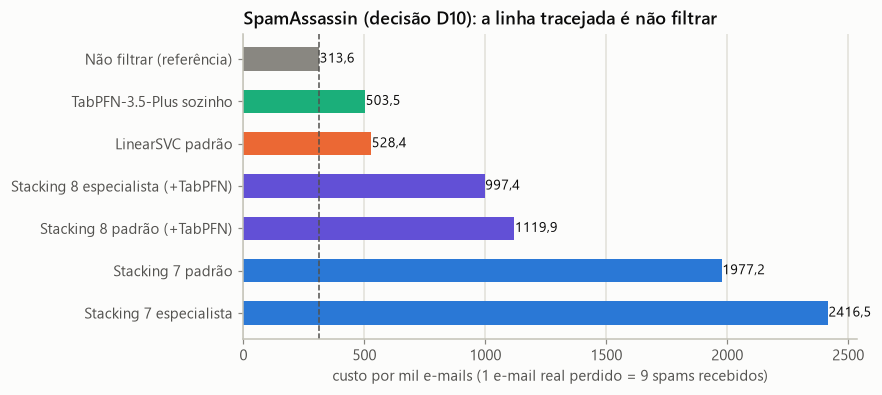

In [12]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ordem = R.sort_values("custo_por_mil", ascending=False)
cores = [graficos.TINTA_MUDA if "Não filtrar" in n else graficos.CATEGORICA[6] if "8" in n else graficos.CATEGORICA[0] if "Stacking 7" in n
         else graficos.CATEGORICA[2] if "TabPFN" in n else graficos.CATEGORICA[1] for n in ordem.metodo]
ax.barh(range(len(ordem)), ordem.custo_por_mil, height=0.55, color=cores)
for i, v in enumerate(ordem.custo_por_mil):
    ax.text(v + 2, i, f"{v:.1f}".replace(".", ","), va="center", fontsize=9)
ax.axvline(nao_filtrar, color=graficos.TINTA_2, lw=1, ls="--")
ax.set_yticks(range(len(ordem)), ordem.metodo); ax.grid(axis="y", visible=False)
ax.set_xlabel("custo por mil e-mails (1 e-mail real perdido = 9 spams recebidos)")
ax.set_title("SpamAssassin (decisão D10): a linha tracejada é não filtrar")
graficos.mostrar(fig, "08_terceira_base")

In [13]:
saidas.gravar("08_terceira_base", {
    "terceira_base": dict(base="SpamAssassin public corpus 20030228 (easy_ham, easy_ham_2, hard_ham, spam, spam_2)",
                          n=int(len(ysa)), n_email_real=int((ysa == 0).sum()), n_spam=int((ysa == 1).sum()),
                          copias_csv_removidas=int((~mantidas).sum()), tem_tabpfn=tem_tabpfn,
                          metodos=R, decisao=decisao, nao_filtrar_custo=nao_filtrar, sensibilidade_custo=LAM,
                          por_pasta=PASTAS, membros=MEMB, controle_dentro_da_base=dentro, cobertura_vocabulario=cob,
                          conversor_spam=CONV, fontes_spam=FONTES, semelhanca_spam=SEMEL),
}, fonte="scripts/08_terceira_base.py")
saidas.gravar_csv("08_terceira_base", R)
print("gravado: resultados/08_terceira_base.json")

gravado: resultados/08_terceira_base.json
